# Aprendizaje por refuerzos — Clase 1: decisiones secuenciales

Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4ª edición, capítulos 15, 16 y 23. Sutton & Barto, *Reinforcement Learning: An Introduction*, 2ª edición, capítulos 2, 3, 4 y 6.

> **Notación.** Usamos la de Sutton y Barto. Russell y Norvig llaman *utilidad* al valor de un estado: su $U^\pi(s)$ y $U(s)$ son nuestros $v_\pi(s)$ y $v_*(s)$, su $Q(s,a)$ es $q_*(s,a)$, y escriben el modelo como $P(s' \mid s,a)$ y $R(s,a,s')$ en lugar de $p(s',r \mid s,a)$. Las mayúsculas $V$ y $Q$ son estimaciones que el agente va aprendiendo. La única excepción es la primera sección: Sutton y Barto no tratan la teoría de la utilidad, así que ahí $U$ es la utilidad de un resultado, como en Russell y Norvig.

Es un tipo de Inteligencia Artificial (IA) donde un **agente** aprende qué decisiones tomar (**política**) dada una situación para maximizar la **recompensa** a largo plazo.




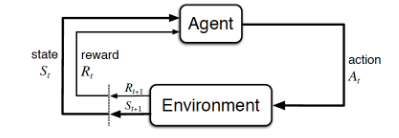




## Términos clave:
**POLÍTICA** ($\pi$): define el comportamiento del agente. Dado el estado del sistema, determina qué acción tomar.

**RECOMPENSA** ($R$): Como resultado de una acción podemos tener una recompensa (valor positivo) o una penalización (valor negativo).

**FUNCIÓN DE VALOR** ($v_\pi(s)$): asociada a un estado, determina qué tan bueno es ese estado en el largo plazo. Es la recompensa total que un agente puede
esperar acumular  partiendo desde ese estado.

**MODELO DEL MUNDO**: permite predecir el próximo estado y recompensa, dado un estado actual y una acción tomada. No siempre se dispone de un modelo del mundo.

**OBJETIVO**: determinar una POLÍTICA óptima (maximice las recompensas recibidas en el largo plazo)


# DECISIONES BAJO INCERTIDUMBRE: UTILIDAD

En las unidades anteriores el agente conocía el resultado de cada acción: si en el mapa de Rumania tomaba la ruta de Arad a Sibiu, llegaba a Sibiu. En la mayoría de los problemas reales esto no pasa: la misma acción puede llevar a resultados distintos, cada uno con cierta probabilidad.

### Teoría:
Para decidir en estas condiciones necesitamos dos cosas:

- Una **utilidad** $U(s)$, que mide qué tan deseable es cada resultado $s$ para el agente.
- Un **modelo de probabilidades** $p(s' \mid a)$, que dice con qué probabilidad la acción $a$ lleva al resultado $s'$.

Con eso se define la **utilidad esperada** de una acción como el promedio de las utilidades de sus resultados, pesadas por su probabilidad:

$$
EU(a) = \sum_{s'} p(s' \mid a)\, U(s')
$$

El **principio de máxima utilidad esperada** (MEU) dice que un agente racional elige la acción que maximiza la utilidad esperada:

$$
a^* = \arg\max_a EU(a)
$$

### Ejemplo: elegir entre dos apuestas
Nos ofrecen dos opciones:

- **A**: recibir 50 pesos seguros.
- **B**: tirar una moneda; si sale cara recibimos 120 pesos, si sale ceca no recibimos nada.

Si la utilidad es el dinero, $EU(A) = 50$ y $EU(B) = 0.5 \cdot 120 + 0.5 \cdot 0 = 60$, así que conviene B. Eso no quiere decir que con B siempre ganemos más: quiere decir que **jugando muchas veces**, en promedio, B rinde más. Veámoslo simulando:

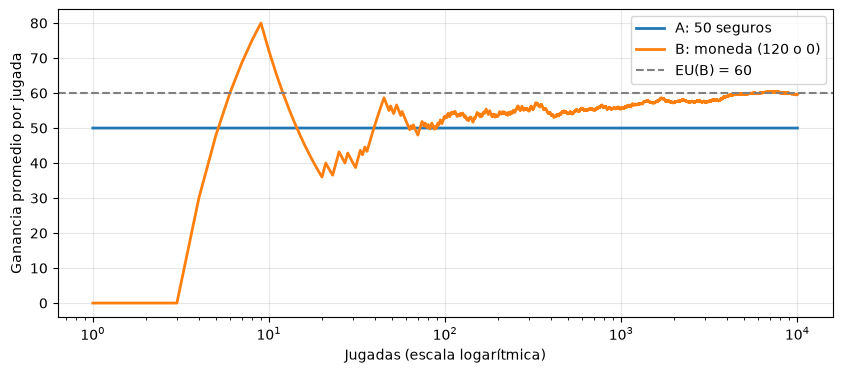

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
jugadas = 10000

ganancia_A = np.full(jugadas, 50.0)                    # siempre 50
ganancia_B = rng.choice([120.0, 0.0], size=jugadas)    # 120 o 0, con probabilidad 0.5 cada uno

# Promedio acumulado: cuánto ganamos por jugada, en promedio, después de n jugadas
n = np.arange(1, jugadas + 1)
plt.figure(figsize=(10, 4))
plt.plot(n, np.cumsum(ganancia_A) / n, label="A: 50 seguros", linewidth=2)
plt.plot(n, np.cumsum(ganancia_B) / n, label="B: moneda (120 o 0)", linewidth=2)
plt.axhline(60, color="gray", linestyle="--", label="EU(B) = 60")
plt.xscale("log")
plt.xlabel("Jugadas (escala logarítmica)")
plt.ylabel("Ganancia promedio por jugada")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

El promedio de B arranca muy ruidoso, pero se acerca a 60, su utilidad esperada. Se acerca despacio: el error típico del promedio es $60/\sqrt{n}$, así que para reducirlo a la mitad hacen falta cuatro veces más jugadas. Con 1000 jugadas todavía puede quedar varios pesos lejos de 60; por eso el gráfico llega a 10000 y usa escala logarítmica. Esa idea la vamos a usar todo el tiempo: **el valor de una acción es lo que rinde en promedio a la larga**.

La utilidad no tiene por qué ser el dinero. Alguien que necesita sí o sí 50 pesos hoy puede preferir A, y no es irracional: su utilidad no crece igual que el dinero. La función de utilidad es la que expresa las preferencias del agente.

En lo que sigue aparecen dos dificultades más:

1. **No conocemos las probabilidades.** Si no sabemos si la moneda está cargada, la única forma de estimar $EU(B)$ es jugar y promediar. Es lo que pasa con las máquinas tragamonedas que vienen a continuación.
2. **Las decisiones se encadenan.** El resultado de una acción es el estado desde el que se toma la siguiente decisión, y la utilidad depende de toda la secuencia. Eso nos lleva a los procesos de decisión de Markov.

# COMPROMISO ENTRE EXPLORACIÓN Y EXPLOTACIÓN

**Exploración**: elegir una acción que no es la greedy, para mejorar la estimación de su valor.

**Explotación**: elegir la acción greedy, es decir, aprovechar lo que ya se sabe.

**Acción greedy**: la acción de mayor **valor estimado** hasta el momento. No es necesariamente la de mayor recompensa real: puede ser una que tuvo suerte en las primeras jugadas.

## Caso de ejemplo: Máquinas tragamonedas

Supongamos que tenemos k máquinas tragamonedas donde la recompensa que devuelve cada una está dada por una distribución normal con varianza igual a 1 y una media propia de cada máquina.

Valores verdaderos de las acciones: [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]


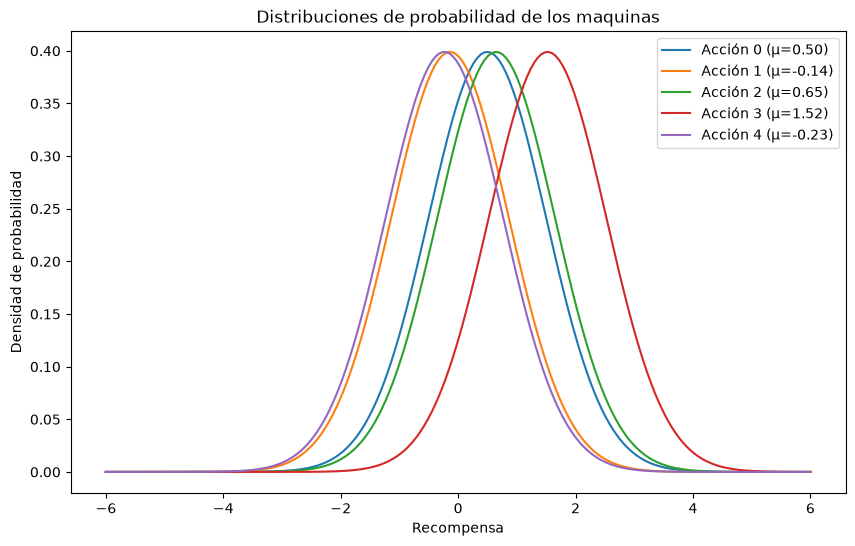

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# --- Configuración ---
np.random.seed(42)
k = 5  # Cantidad de máquinas
recompensa_media_maquina = np.random.normal(0, 1, k)   # tomamos k medias de una distribucion normal
variance = 1.0                             # varianza de las recompensas

print (f"Valores verdaderos de las acciones: {recompensa_media_maquina}")

# --- Graficar distribuciones ---
x = np.linspace(-6, 6, 200)  # rango de valores posibles de recompensa

plt.figure(figsize=(10,6))
for i in range(k):
    y = norm.pdf(x, loc=recompensa_media_maquina[i], scale=np.sqrt(variance))
    plt.plot(x, y, label=f"Acción {i} (μ={recompensa_media_maquina[i]:.2f})")

plt.title("Distribuciones de probabilidad de los maquinas")
plt.xlabel("Recompensa")
plt.ylabel("Densidad de probabilidad")
plt.legend()
plt.show()

Así, por ejemplo, si juego muchas veces en la máquina 0 voy a terminar con una ganancia de 0.5 en promedio. Si juego suficientes veces a la máquina 1 voy a terminar con una pérdida promedio de 0.14.

La idea es encontrar un algoritmo que termine encontrando la máquina que da mayor recompensa en la menor cantidad de pasos, maximizando el beneficio, teniendo en cuenta que las recompensas responden a una función aleatoria.

## Estimación de recompensa

El **valor** de una acción _a_ es la recompensa que da en promedio: $q_*(a) = E[R_t \mid A_t = a]$. Como no lo conocemos, lo estimamos. El valor estimado de la acción _a_ en el paso _t_ es $Q_t(a)$:

$$
Q_t(a) = 
\frac{\sum_{i=1}^{t-1} R_i \, \mathbf{1}\{A_i = a\}}
     {\sum_{i=1}^{t-1} \mathbf{1}\{A_i = a\}}
$$

O sea, la recompensa para la acción _a_ se puede estimar como el promedio de las recompensas obtenidas por esa acción.

## Acción greedy
### Teoría:
La acción **Greedy** es la acción cuyo promedio de recompensas es mayor hasta el momento _t_.

La acción greedy se puede escribir de forma matemática como:
$A_g = \arg\max_{a} Q_t(a)$, siendo esta la acción con la cual se obtiene el máximo Q hasta el momento.


### Simulación:
Vamos a hacer un ejemplo donde un agente tiene como política elegir la acción greedy.

Para esto definimos una función donde tome como argumento el número de máquina elegido y me devuelva una recompensa según su distribución de probabilidad.


In [3]:
def maquina(action):
    return np.random.normal(recompensa_media_maquina[action], 1.0)


Definamos la función para la política greedy, inicializando en cero las recompensas esperadas Q para cada máquina y el número de intentos:

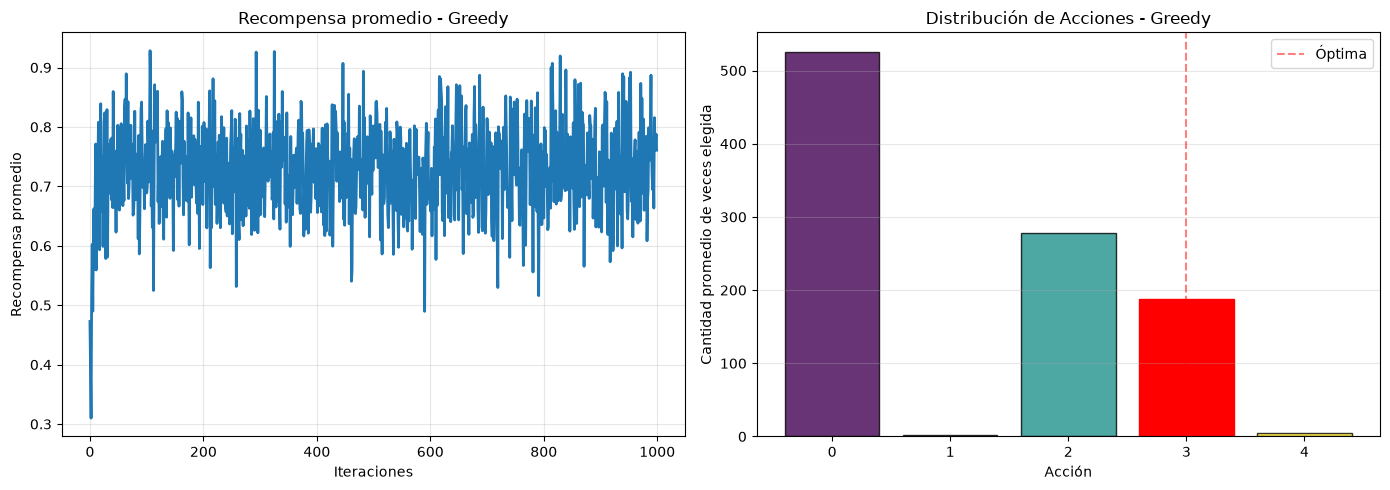

Acción más elegida: 0 (525.9 veces)
Porcentaje en acción óptima: 18.8%


In [4]:
steps = 1000 # Cantidad de pasos de la simulación
runs = 200   # Cantidad de simulaciones

# --- Política greedy ---
def run_greedy():
    Q = np.zeros(k) # Vector de recompensas esperadas
    N = np.zeros(k) # Vector de visitas
    rewards = []    # Vector de recompensas

    for t in range(1, steps+1): # Para cada iteración
        action = np.argmax(Q)   # Busco la acción que devuelva la mayor recompensa esperada
        r = maquina(action)     # Uso esa máquina y guardo la recompensa
        N[action] += 1          # Le sumo una visita a la acción
        Q[action] += (r - Q[action]) / N[action] # Actualizo la recompensa esperada para la acción
        rewards.append(r)       # Guardo la recompensa para armar un historico
    return rewards, N

# --- Simulación ---
avg_rewards_greedy = np.zeros(steps)
total_actions_greedy = np.zeros(k)

for _ in range(runs):
    rewards_g, actions_g = run_greedy()
    avg_rewards_greedy += rewards_g
    total_actions_greedy += actions_g

avg_rewards_greedy /= runs
total_actions_greedy /= runs

optimal_action = np.argmax(recompensa_media_maquina)

# --- Gráficos ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recompensas promedio
axes[0].plot(avg_rewards_greedy, label="Greedy", linewidth=2)
axes[0].set_xlabel("Iteraciones")
axes[0].set_ylabel("Recompensa promedio")
axes[0].set_title("Recompensa promedio - Greedy")
axes[0].grid(alpha=0.3)

# Distribución de acciones
colors = plt.cm.viridis(np.linspace(0, 1, k))
bars = axes[1].bar(range(k), total_actions_greedy, color=colors, alpha=0.8, edgecolor='black')
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
axes[1].set_xlabel("Acción")
axes[1].set_ylabel("Cantidad promedio de veces elegida")
axes[1].set_title("Distribución de Acciones - Greedy")
axes[1].axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Estadísticas ---
most_chosen = np.argmax(total_actions_greedy)
print(f"Acción más elegida: {most_chosen} ({total_actions_greedy[most_chosen]:.1f} veces)")
print(f"Porcentaje en acción óptima: {100*total_actions_greedy[optimal_action]/steps:.1f}%")


### Algunas preguntas:

La acción más elegida no es la óptima. ¿Por qué?

¿Por qué las acciones 1 y 4 casi no se eligen?



## Política ε-greedy

### Teoría:
La política ε-greedy consiste en:

$A_t =
\begin{cases}
\arg\max_{a} Q_t(a), & \text{con probabilidad } 1-\varepsilon \\
\text{acción aleatoria}, & \text{con probabilidad } \varepsilon
\end{cases}$

En cada paso tengo una probabilidad ($1-\varepsilon$) de usar la acción greedy (explotar) y una probabilidad $\varepsilon$ de usar una acción aleatoria (explorar).

Si los pasos en el ciclo tienden a infinito ($t \to \infty$) entonces la acción greedy tiende a la acción óptima (la de mayor recompensa), porque recorrí todas las acciones suficientes veces como para encontrar la óptima.

### Simulación:


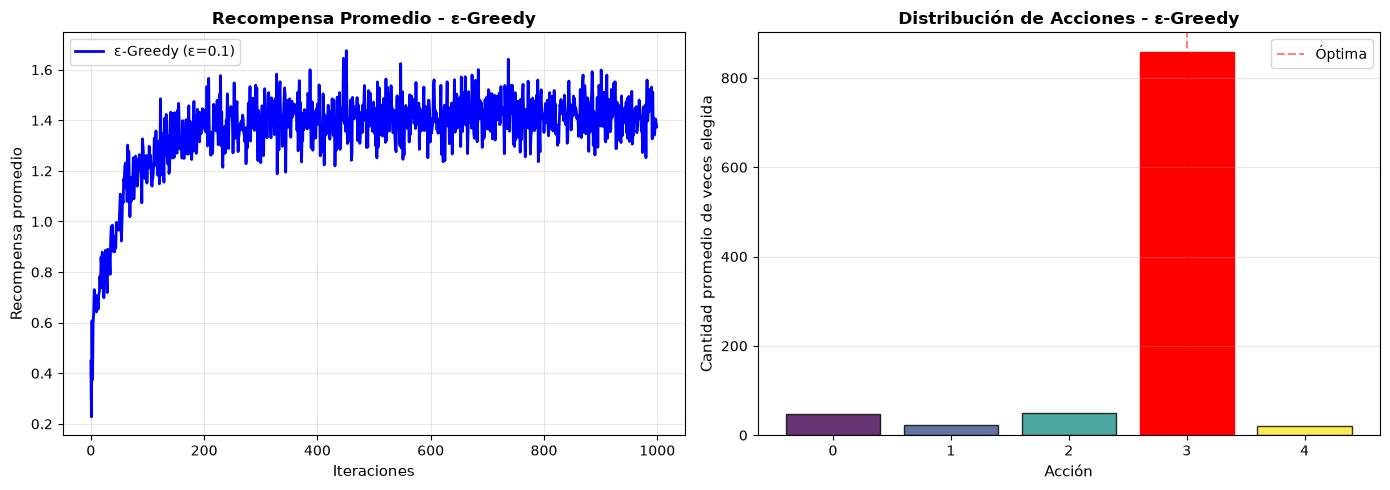

ε-GREEDY (ε=0.1):
  Acción más elegida: 3 (859.2 veces)
  Porcentaje en acción óptima: 85.9%


In [5]:
steps = 1000
runs = 200

def run_epsilon_greedy(epsilon=0.1):
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    for t in range(1, steps+1):
        if np.random.rand() < epsilon:
            action = np.random.randint(k)
        else:
            action = np.argmax(Q)
        r = maquina(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, N

# --- Simulación ---
avg_rewards_eps = np.zeros(steps)
total_actions_eps = np.zeros(k)

for _ in range(runs):
    rewards_e, actions_e = run_epsilon_greedy(0.1)
    avg_rewards_eps += rewards_e
    total_actions_eps += actions_e

avg_rewards_eps /= runs
total_actions_eps /= runs

# --- Gráficos ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recompensas promedio
axes[0].plot(avg_rewards_eps, label="ε-Greedy (ε=0.1)", color='blue', linewidth=2)
axes[0].set_xlabel("Iteraciones", fontsize=11)
axes[0].set_ylabel("Recompensa promedio", fontsize=11)
axes[0].set_title("Recompensa Promedio - ε-Greedy", fontsize=12, fontweight='bold')
axes[0].grid(alpha=0.3)
axes[0].legend()

# Distribución de acciones
colors = plt.cm.viridis(np.linspace(0, 1, k))
bars = axes[1].bar(range(k), total_actions_eps, color=colors, alpha=0.8, edgecolor='black')
optimal_action = np.argmax(recompensa_media_maquina)
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
axes[1].set_xlabel("Acción", fontsize=11)
axes[1].set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
axes[1].set_title("Distribución de Acciones - ε-Greedy", fontsize=12, fontweight='bold')
axes[1].set_xticks(range(k))
axes[1].axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Resumen ---
most_chosen = np.argmax(total_actions_eps)
print(f"ε-GREEDY (ε=0.1):")
print(f"  Acción más elegida: {most_chosen} ({total_actions_eps[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_eps[optimal_action]/steps:.1f}%")


### Preguntas:
¿Qué hizo que en este caso se encuentre la acción de mayor recompensa?

¿Cuántas iteraciones fueron necesarias para lograrlo?


## Política UCB

### Teoría:
El método UCB (Upper-Confidence-Bound) selecciona la acción que maximiza no solo la recompensa promedio estimada, sino también un término de exploración que da más valor a las acciones menos probadas.

La acción elegida en un paso _t_ estará dada por:

$A_t = \arg\max_a \left[ \, Q_t(a) + c \, \sqrt{\frac{\ln t}{N_t(a)}} \, \right]$

Donde:
- $Q_t(a)$: valor estimado de la acción $a$ hasta el tiempo $t$  
- $N_t(a)$: número de veces que la acción $a$ fue seleccionada antes de $t$  
- $t$: número total de pasos hasta el momento  
- $c > 0$: parámetro que controla cuánta **exploración** queremos  

De la ecuación podemos observar lo siguiente:
- $Q_t(a)$ → premia acciones que parecen buenas  
- $\sqrt{\tfrac{\ln t}{N_t(a)}}$ → premia acciones poco probadas  
- El parámetro $c$ ajusta cuánto valoramos explorar  

### Simulación y comparación con métodos anteriores:

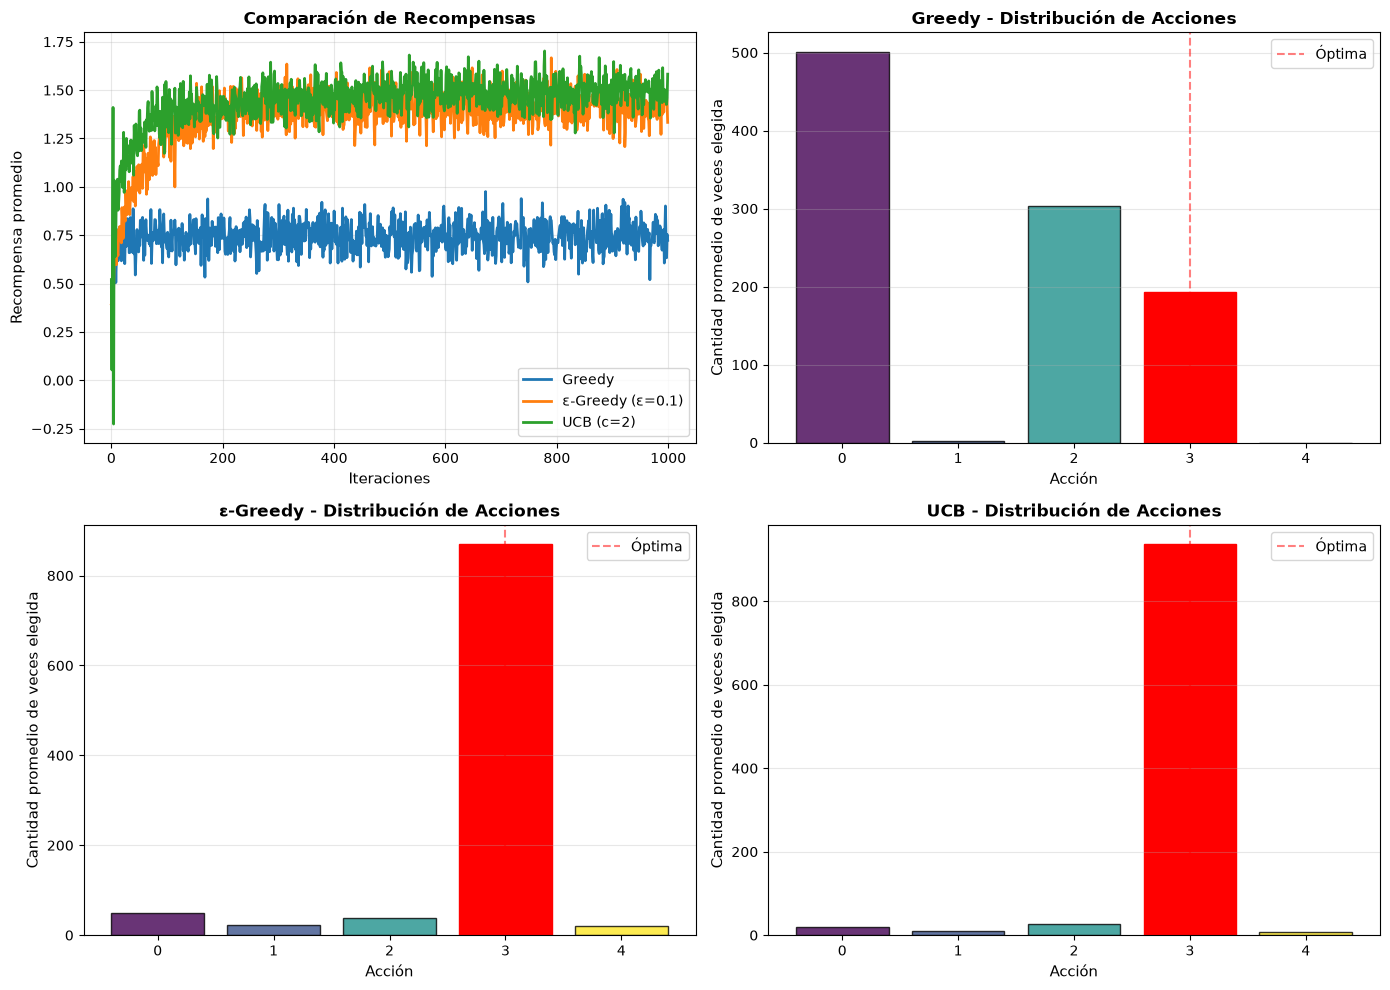


────────────────────────────────────────────────────────────

GREEDY:
  Acción más elegida: 0 (500.9 veces)
  Porcentaje en acción óptima: 19.3%

ε-GREEDY (ε=0.1):
  Acción más elegida: 3 (869.4 veces)
  Porcentaje en acción óptima: 86.9%

UCB (c=2):
  Acción más elegida: 3 (936.3 veces)
  Porcentaje en acción óptima: 93.6%


In [6]:
steps = 1000         # cantidad de iteraciones
runs = 200          # cantidad de simulaciones para promediar

def maquina(action):
    """Devuelve una recompensa al tomar la acción (ruido gaussiano agregado)."""
    return np.random.normal(recompensa_media_maquina[action], 1.0)

# --- Algoritmos (modificados para trackear acciones) ---
def run_greedy():
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    action_counts = np.zeros(k)  # contador de acciones

    for t in range(1, steps+1):
        action = np.argmax(Q)
        r = maquina(action)
        N[action] += 1
        action_counts[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, action_counts

def run_epsilon_greedy(epsilon=0.1):
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    action_counts = np.zeros(k)

    for t in range(1, steps+1):
        if np.random.rand() < epsilon:
            action = np.random.randint(k)
        else:
            action = np.argmax(Q)
        r = maquina(action)
        N[action] += 1
        action_counts[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, action_counts

def run_ucb(c=2):
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    action_counts = np.zeros(k)

    for t in range(1, steps+1):
        if 0 in N:
            action = np.argmin(N)
        else:
            ucb_values = Q + c * np.sqrt(np.log(t) / N)
            action = np.argmax(ucb_values)
        r = maquina(action)
        N[action] += 1
        action_counts[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, action_counts

# --- Simulación ---
avg_rewards_greedy = np.zeros(steps)
avg_rewards_eps = np.zeros(steps)
avg_rewards_ucb = np.zeros(steps)

# Acumuladores para las acciones
total_actions_greedy = np.zeros(k)
total_actions_eps = np.zeros(k)
total_actions_ucb = np.zeros(k)

for _ in range(runs):
    rewards_g, actions_g = run_greedy()
    rewards_e, actions_e = run_epsilon_greedy(0.1)
    rewards_u, actions_u = run_ucb(2)

    avg_rewards_greedy += rewards_g
    avg_rewards_eps += rewards_e
    avg_rewards_ucb += rewards_u

    total_actions_greedy += actions_g
    total_actions_eps += actions_e
    total_actions_ucb += actions_u

avg_rewards_greedy /= runs
avg_rewards_eps /= runs
avg_rewards_ucb /= runs

total_actions_greedy /= runs
total_actions_eps /= runs
total_actions_ucb /= runs

# --- Gráficos ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Gráfico de recompensas (como antes)
ax1 = axes[0, 0]
ax1.plot(avg_rewards_greedy, label="Greedy", linewidth=2)
ax1.plot(avg_rewards_eps, label="ε-Greedy (ε=0.1)", linewidth=2)
ax1.plot(avg_rewards_ucb, label="UCB (c=2)", linewidth=2)
ax1.set_xlabel("Iteraciones", fontsize=11)
ax1.set_ylabel("Recompensa promedio", fontsize=11)
ax1.set_title("Comparación de Recompensas", fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

# 2. Distribución de acciones - Greedy
ax2 = axes[0, 1]
colors = plt.cm.viridis(np.linspace(0, 1, k))
bars = ax2.bar(range(k), total_actions_greedy, color=colors, alpha=0.8, edgecolor='black')
optimal_action = np.argmax(recompensa_media_maquina)
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
ax2.set_xlabel("Acción", fontsize=11)
ax2.set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
ax2.set_title("Greedy - Distribución de Acciones", fontsize=12, fontweight='bold')
ax2.set_xticks(range(k))
ax2.axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# 3. Distribución de acciones - ε-Greedy
ax3 = axes[1, 0]
bars = ax3.bar(range(k), total_actions_eps, color=colors, alpha=0.8, edgecolor='black')
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
ax3.set_xlabel("Acción", fontsize=11)
ax3.set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
ax3.set_title("ε-Greedy - Distribución de Acciones", fontsize=12, fontweight='bold')
ax3.set_xticks(range(k))
ax3.axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# 4. Distribución de acciones - UCB
ax4 = axes[1, 1]
bars = ax4.bar(range(k), total_actions_ucb, color=colors, alpha=0.8, edgecolor='black')
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
ax4.set_xlabel("Acción", fontsize=11)
ax4.set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
ax4.set_title("UCB - Distribución de Acciones", fontsize=12, fontweight='bold')
ax4.set_xticks(range(k))
ax4.axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
ax4.legend()
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


print(f"\n{'─'*60}")
print("\nGREEDY:")
most_chosen = np.argmax(total_actions_greedy)
print(f"  Acción más elegida: {most_chosen} ({total_actions_greedy[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_greedy[optimal_action]/steps:.1f}%")

print(f"\nε-GREEDY (ε=0.1):")
most_chosen = np.argmax(total_actions_eps)
print(f"  Acción más elegida: {most_chosen} ({total_actions_eps[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_eps[optimal_action]/steps:.1f}%")

print(f"\nUCB (c=2):")
most_chosen = np.argmax(total_actions_ucb)
print(f"  Acción más elegida: {most_chosen} ({total_actions_ucb[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_ucb[optimal_action]/steps:.1f}%")
print("="*60)

### Preguntas
¿Por qué la recompensa media de UCB es mayor a la de ε-greedy?


# DECISIONES SECUENCIALES

En las tragamonedas cada decisión era independiente de la anterior: jugar en una máquina no cambia la situación en la que estamos. En la mayoría de los problemas, en cambio, cada acción nos lleva a un nuevo estado, y desde ahí hay que volver a decidir.

## Ejemplo: el mundo 4×3
(Russell & Norvig, sección 16.1)

Un agente se mueve en una grilla de 4×3. Empieza en la casilla (1,1), abajo a la izquierda, y el juego termina cuando llega a una de las dos casillas terminales: (4,3), con recompensa **+1**, o (4,2), con recompensa **−1**. La casilla (2,2) es una pared.

```
        1     2     3     4
     +-----+-----+-----+-----+
  3  |     |     |     | +1  |
     +-----+-----+-----+-----+
  2  |     |#####|     | -1  |
     +-----+-----+-----+-----+
  1  |  S  |     |     |     |
     +-----+-----+-----+-----+
```

Las acciones son Arriba, Abajo, Izquierda y Derecha, pero **no son confiables**: con probabilidad 0.8 el agente se mueve en la dirección elegida, y con probabilidad 0.1 se desvía hacia cada uno de los costados. Si choca contra la pared o el borde, se queda donde estaba.

Si el mundo fuera determinista, la solución sería un **plan** como los de búsqueda: [Arriba, Arriba, Derecha, Derecha, Derecha]. Con acciones que fallan, ese plan sale bien solo si las cinco acciones salen bien, con probabilidad $0.8^5 \approx 0.33$ (un poco más, contando los caminos que llegan de casualidad). Simulemos:

In [7]:
# El mundo 4x3. Las casillas son (columna, fila), como en el libro.
PARED = (2, 2)
TERMINALES = {(4, 3): +1.0, (4, 2): -1.0}

MOVIMIENTOS = {"↑": (0, 1), "↓": (0, -1), "←": (-1, 0), "→": (1, 0)}
COSTADOS = {"↑": ("←", "→"), "↓": ("→", "←"), "←": ("↓", "↑"), "→": ("↑", "↓")}

def mover(s, accion):
    # Casilla a la que se llega moviéndose desde s. Si hay pared o borde, se queda.
    dx, dy = MOVIMIENTOS[accion]
    destino = (s[0] + dx, s[1] + dy)
    if destino == PARED or not (1 <= destino[0] <= 4 and 1 <= destino[1] <= 3):
        return s
    return destino

def paso(s, accion, rng):
    # Ejecuta la acción: 0.8 va hacia donde se eligió, 0.1 a cada costado.
    izq, der = COSTADOS[accion]
    destinos = [mover(s, accion), mover(s, izq), mover(s, der)]
    return destinos[rng.choice(3, p=[0.8, 0.1, 0.1])]

def ejecutar_plan(plan, rng):
    s = (1, 1)
    for accion in plan:
        s = paso(s, accion, rng)
        if s in TERMINALES:
            break
    return s

rng = np.random.default_rng(0)
plan = ["↑", "↑", "→", "→", "→"]
episodios = 100_000

llegadas = sum(ejecutar_plan(plan, rng) == (4, 3) for _ in range(episodios))
print(f"El plan llega a +1 en el {100 * llegadas / episodios:.1f}% de los intentos")

El plan llega a +1 en el 32.7% de los intentos


Dos de cada tres veces el plan falla, y cuando falla el agente queda en una casilla cualquiera sin saber qué hacer. Lo que necesitamos no es una secuencia fija de acciones sino una **política** $\pi(s)$: una regla que diga qué hacer **en cada estado** al que se pueda llegar. Así, si una acción sale mal, el agente consulta la política en el estado donde quedó y sigue.

La siguiente es la política óptima que muestra el libro cuando cada paso tiene un costo de 0.04 (figura 16.2). En realidad el libro dibuja dos, que solo difieren en (3,1): ahí da por equivalentes ir a la izquierda y subir. Acá usamos la de la izquierda:

In [8]:
politica = {(1, 3): "→", (2, 3): "→", (3, 3): "→",
            (1, 2): "↑",              (3, 2): "↑",
            (1, 1): "↑", (2, 1): "←", (3, 1): "←", (4, 1): "←"}

def dibujar_politica(politica):
    for y in (3, 2, 1):
        fila = []
        for x in (1, 2, 3, 4):
            if (x, y) == PARED:
                fila.append("■")
            elif (x, y) in TERMINALES:
                fila.append(f"{TERMINALES[(x, y)]:+.0f}")
            else:
                fila.append(politica[(x, y)])
        print("  ".join(f"{c:>2}" for c in fila))

def ejecutar_politica(politica, rng, max_pasos=100):
    s, pasos = (1, 1), 0
    while s not in TERMINALES and pasos < max_pasos:
        s = paso(s, politica[s], rng)
        pasos += 1
    return s, pasos

dibujar_politica(politica)

resultados = [ejecutar_politica(politica, rng) for _ in range(episodios)]
llegadas = sum(s == (4, 3) for s, _ in resultados)
print(f"\nLa política llega a +1 en el {100 * llegadas / episodios:.1f}% de los intentos")
print(f"Pasos promedio por episodio: {np.mean([p for _, p in resultados]):.1f}")

 →   →   →  +1
 ↑   ■   ↑  -1
 ↑   ←   ←   ←



La política llega a +1 en el 98.6% de los intentos
Pasos promedio por episodio: 6.7


### Preguntas:
La política llega casi siempre a +1, pero tarda más pasos que el plan. ¿Por qué desde (3,1) elige ir hacia la izquierda y dar toda la vuelta, en vez de subir por (3,2)?

¿Qué debería pasar con la política si cada paso costara mucho más, por ejemplo 0.5?

## Recompensas y retorno

¿Cómo se mide qué tan buena es una secuencia de estados? En aprendizaje por refuerzo el agente recibe una **recompensa** $R_{t+1}$ después de cada acción, y la utilidad de la secuencia es el **retorno**: la suma de las recompensas que vienen, descontadas.

$$
G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \cdots = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1}
$$

En el mundo 4×3 cada paso da una recompensa de −0.04 (un pequeño costo por moverse), y al entrar en una casilla terminal se recibe +1 o −1.

El **factor de descuento** $\gamma \in [0, 1]$ indica cuánto valen las recompensas futuras comparadas con las inmediatas:

- Con $\gamma = 1$ todas pesan lo mismo. Sirve en **tareas episódicas**, que siempre terminan, como el mundo 4×3 o una partida de un juego.
- Con $\gamma < 1$, una recompensa que llega dentro de $k$ pasos vale $\gamma^k$ veces lo que valdría ahora. Es imprescindible en **tareas continuas**, que no terminan nunca: sin descuento la suma podría ser infinita. Además expresa una preferencia razonable: mejor ganar antes que después.

### Ejemplo:
Calculemos el retorno de tres episodios posibles desde (1,1): el camino corto hasta +1 (5 pasos), uno más largo de 7 pasos (dos acciones salieron mal y hubo que corregir) y uno que termina cayendo en −1.

In [9]:
def retorno(recompensas, gamma):
    # G_0 = R_1 + gamma R_2 + gamma^2 R_3 + ...
    return sum(gamma**k * r for k, r in enumerate(recompensas))

camino_corto = [-0.04] * 4 + [1.0]      # 4 pasos comunes y el último entra en +1
camino_largo = [-0.04] * 6 + [1.0]      # dos desvíos: 6 pasos comunes y el último entra en +1
cae_en_menos_uno = [-0.04] * 4 + [-1.0]

for gamma in (1.0, 0.9, 0.5):
    print(f"gamma = {gamma}:  corto {retorno(camino_corto, gamma):+.3f}   "
          f"largo {retorno(camino_largo, gamma):+.3f}   "
          f"cae en -1 {retorno(cae_en_menos_uno, gamma):+.3f}")

gamma = 1.0:  corto +0.840   largo +0.760   cae en -1 -1.160
gamma = 0.9:  corto +0.519   largo +0.344   cae en -1 -0.794
gamma = 0.5:  corto -0.013   largo -0.063   cae en -1 -0.138


### Preguntas:
¿Qué pasa con la diferencia entre el camino corto y el largo a medida que $\gamma$ baja? ¿Qué tipo de política esperarían con un $\gamma$ muy chico?

Como las acciones son aleatorias, el retorno también lo es: la misma política puede dar episodios cortos, largos o terminar en −1. Por eso una política se evalúa por su retorno **esperado**. Eso es la función de valor, que definimos formalmente a continuación.

# Procesos de Markov


En un proceso de Markov el estado actual del entorno (environment) caracteriza completamente la evolución del proceso (independientemente del pasado / camino recorrido).

En estos procesos el agente se encuentra en un estado ($S_t$) y al interactuar con una acción ($A_t$) de todas las acciones posibles en ese estado ($A_t \in \mathcal{A}$), pasa al estado siguiente ($S_{t+1}$) y obtiene una recompensa ($R_{t+1}$), los cuales responden a una función de probabilidad. En un proceso de decisión de Markov $S_{t+1}$ y $R_{t+1}$ dependen exclusivamente del par estado y acción inmediatamente anterior, $(S_t, A_t)$, y no del resto de la historia del proceso.


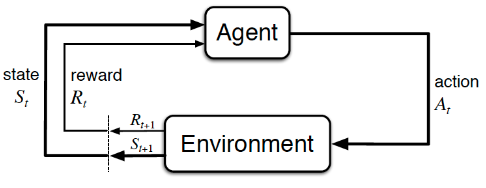


Las máquinas del ejemplo anterior eran Procesos de Decisión de Markov con un único estado.

## Algunos conceptos necesarios:

Un proceso de decisión de Markov (MDP) queda definido por los estados $\mathcal{S}$, las acciones $\mathcal{A}$, la dinámica $p(s', r \mid s, a)$ y el factor de descuento $\gamma$.

* $S_t$: estado en el tiempo (t).
* $A_t$: acción tomada en el tiempo (t).
* $R_{t+1}$: recompensa observada al pasar de $(S_t)$ a $(S_{t+1})$.
* $\mathcal{S}$: espacio de estados.
* $\mathcal{A}(s)$: acciones disponibles en el estado (s).
- $p(s', r \mid s, a)$: dinámica: probabilidad de llegar a $s'$ y recibir la recompensa $r$, desde $s$ tomando la acción $a$. Sumando sobre $r$ sale la probabilidad de transición $p(s' \mid s, a)$.
- $G_t$: Retorno: suma descontada de recompensas futuras, $G_t = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1} = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \cdots$.  
- $\gamma$: factor de descuento, cuánto importa el futuro $(0 \le \gamma \le 1)$.  
- $v_\pi(s) = \mathbb{E}_\pi[G_t \mid S_t=s]$ : Valor de estado: retorno esperado partiendo de s y siguiendo la política π.  
- $\pi(a \mid s)$ : Política: probabilidad de elegir acción a en estado s.  
- $\pi_*(s) = \arg\max_a q_*(s,a)$: Política óptima greedy: elegir la acción con mayor valor óptimo.



La Ecuación de Bellman establece la relación entre el valor de un estado S y los valores de los posibles estados siguientes s'. La Ecuación de Bellman para una política $\pi$ está dada por:

$$
v_\pi(s) = \sum_a \pi(a|s) \sum_{s',r} p(s',r|s,a) \big[ r + \gamma v_\pi(s') \big]
$$

**Explicación de los términos:**

- $v_π(s)$ valor esperado del estado s siguiendo la política π.  
- $π(a|s)$ probabilidad de elegir la acción a en el estado s según la política π.  
- $p(s',r|s,a)$ probabilidad de que, al tomar acción a en s, el siguiente estado sea s' y se reciba recompensa r.  
- $r$ recompensa inmediata obtenida al pasar de s a s' con acción a.  
- $γ$ factor de descuento, pondera la importancia de las recompensas futuras.  
- $v_π(s')$ valor esperado del siguiente estado s', según la política π.  
- $Σ_a Σ_{s',r}$ promedia sobre todas las acciones posibles y todos los resultados posibles de la acción.


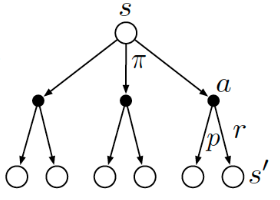

## Valor de estado y valor de acción

La ecuación de Bellman usa el valor de estado $v_\pi(s)$: cuánto retorno esperamos desde $s$ siguiendo $\pi$. Para elegir acciones es más útil el **valor de acción** $q_\pi(s,a)$: el retorno esperado si en el estado $s$ tomamos la acción $a$ y después seguimos la política $\pi$:

$$
q_\pi(s,a) = \mathbb{E}_\pi \big[ G_t \mid S_t=s, A_t=a \big]
$$

Los dos se relacionan de forma directa: el valor de un estado es el promedio de los valores de sus acciones, pesado por la probabilidad con que la política elige cada una:

$$
v_\pi(s) = \sum_a \pi(a|s)\, q_\pi(s,a)
$$

Es la misma idea que el $Q_t(a)$ de las tragamonedas, pero ahora el valor depende del estado.

### Valores óptimos
La **política óptima** $\pi_*$ es la que obtiene el mayor valor en todos los estados. Sus valores, $v_*$ y $q_*$, cumplen la **ecuación de optimalidad de Bellman**: en lugar de promediar según la política, se toma la mejor acción.

$$
v_*(s) = \max_a \sum_{s',r} p(s',r|s,a) \big[ r + \gamma v_*(s') \big]
$$

$$
q_*(s,a) = \sum_{s',r} p(s',r|s,a) \big[ r + \gamma \max_{a'} q_*(s',a') \big]
$$

Si conocemos $q_*$, la política óptima sale directamente, sin necesidad de conocer el modelo del mundo: en cada estado elegimos la acción de mayor valor.

$$
\pi_*(s) = \arg\max_a q_*(s,a)
$$

Esta es la idea detrás de Q-learning, que vemos al final de la clase: aprender $q_*$ a partir de la experiencia.

## a - Programación dinámica: Iteración de valores

Un procedimiento para encontrar la política óptima es el denominado **algoritmo de iteración por valores**. Esto permite calcular numéricamente los valores de los estados y los valores de las acciones en los Procesos de Decisión de Markov (MDPs) con probabilidades de transición y recompensas conocidas. El procedimiento (para los valores de los estados) incluye los siguientes pasos:

1.  **Inicializar** los valores de todos los estados, V(s), con algún valor inicial (generalmente cero).
2.  Para cada estado, *s*, en el MDP, **realizar la actualización de Bellman**:
    
$$
v_{k+1}(s) = \max_a \sum_{s',r} p(s',r|s,a) \big[ r + \gamma v_k(s') \big]
$$

3.  **Repetir** el paso 2 durante un número grande de iteraciones o hasta que los cambios sean demasiado pequeños.

Este algoritmo converge a la solución óptima pero tiene la limitación de que hay que iterar por todos los estados y acciones posibles (computacionalmente costoso), y se tiene que conocer la dinámica $p(s',r|s,a)$ para cada par estado-acción.

Otra alternativa es la **iteración de políticas**, que alterna dos pasos: evaluar la política actual (calcular $v_\pi$ con la ecuación de Bellman) y mejorarla eligiendo en cada estado la acción greedy respecto de esos valores. Se repite hasta que la política deja de cambiar.

Veamos el siguiente ejemplo (Sutton & Barto, ejemplo 4.3, p. 84):

Un jugador tiene la oportunidad de apostar en los resultados de una serie de lanzamientos de moneda. Si la moneda sale cara, gana tantos dólares como haya apostado en ese lanzamiento; si sale cruz, pierde lo apostado. El juego termina cuando el jugador gana al alcanzar su objetivo de $100, o pierde al quedarse sin dinero. En cada lanzamiento, el jugador debe decidir qué porción de su capital apostar, en números enteros de dólares. ¿Cuál es la política que maximice las probabilidades de alcanzar el objetivo?

Apliquemos el método de iteración de valores en este ejemplo:

Iteración 1
Iteración 2
Iteración 3
Iteración 4
Iteración 5
Iteración 6
Iteración 7
Iteración 8
Iteración 9
Iteración 10
Iteración 11
Iteración 12


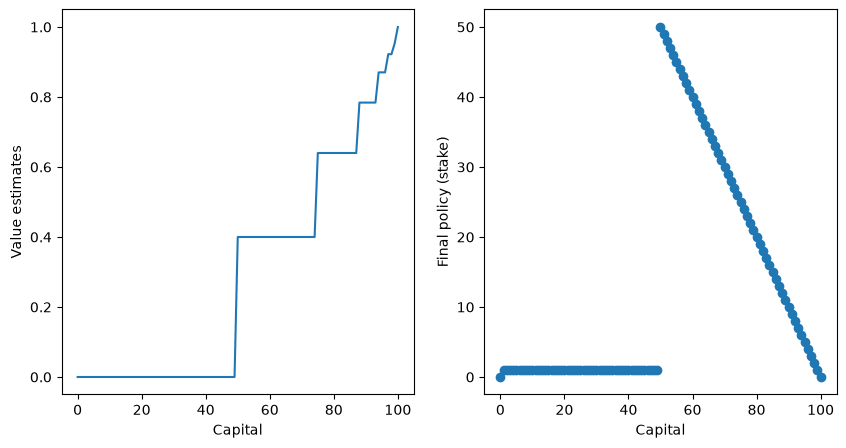

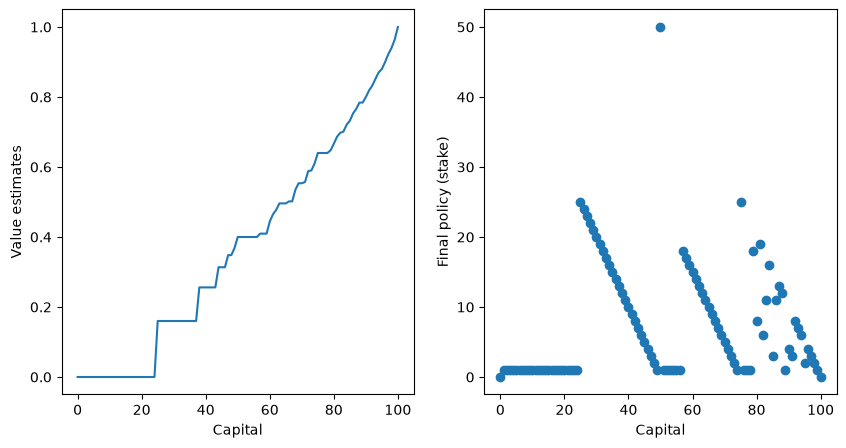

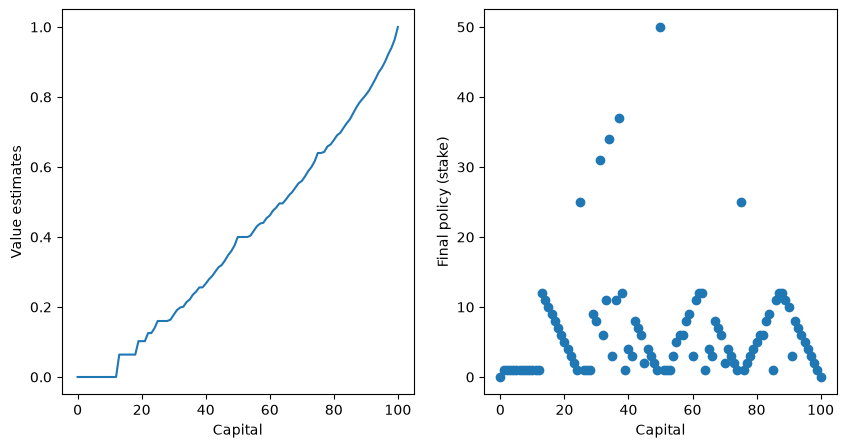

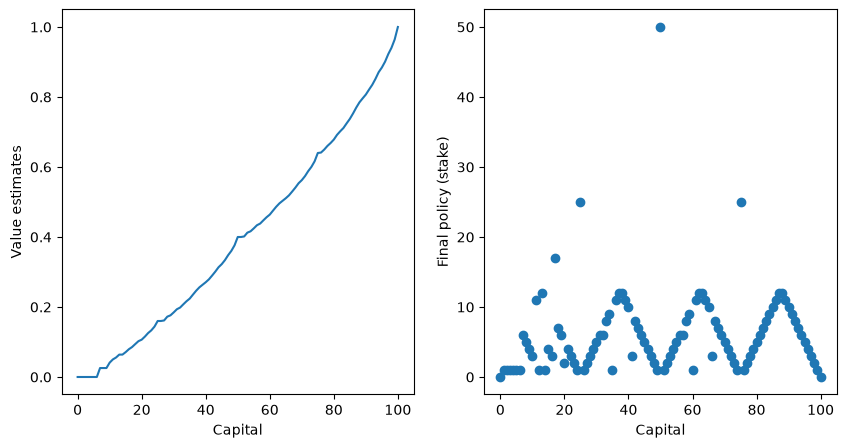

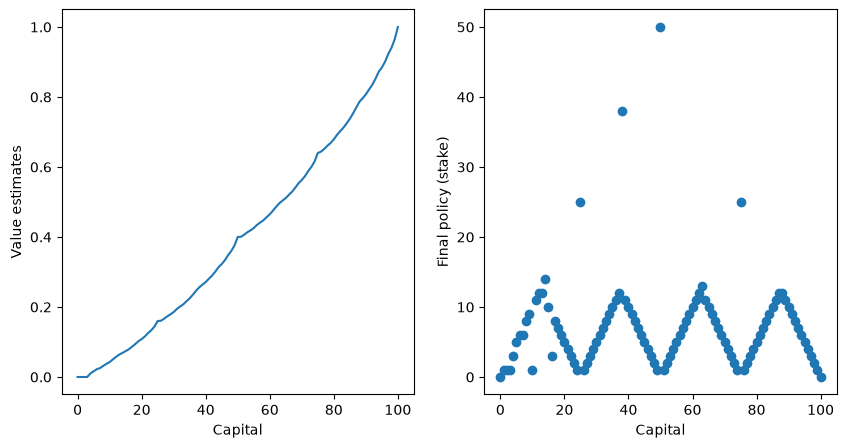

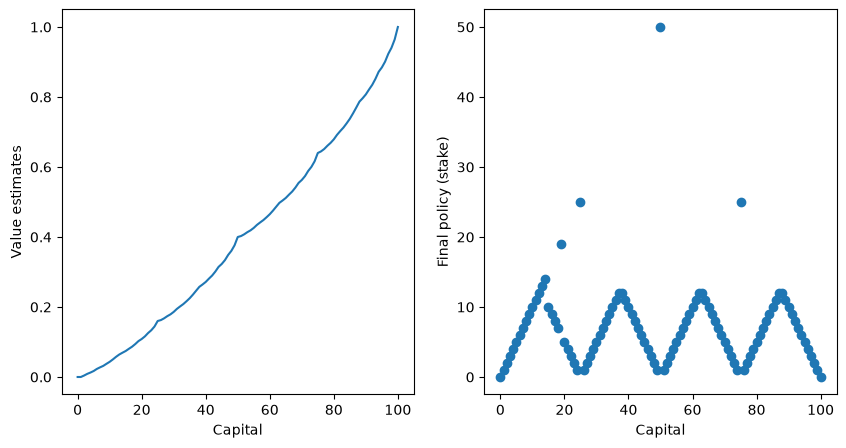

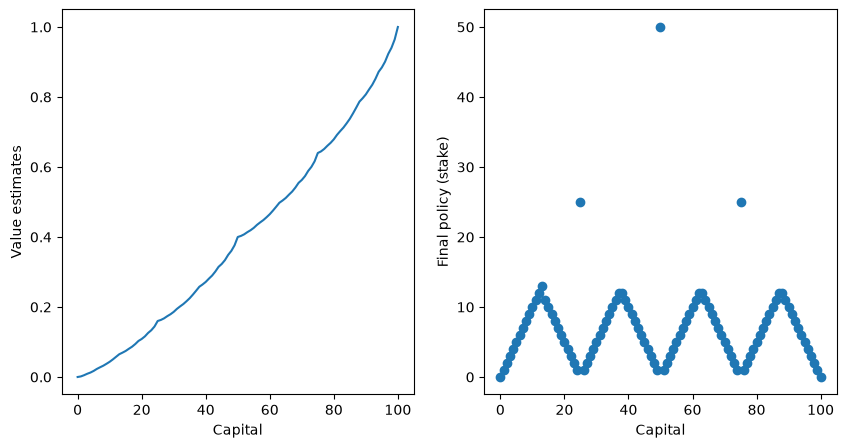

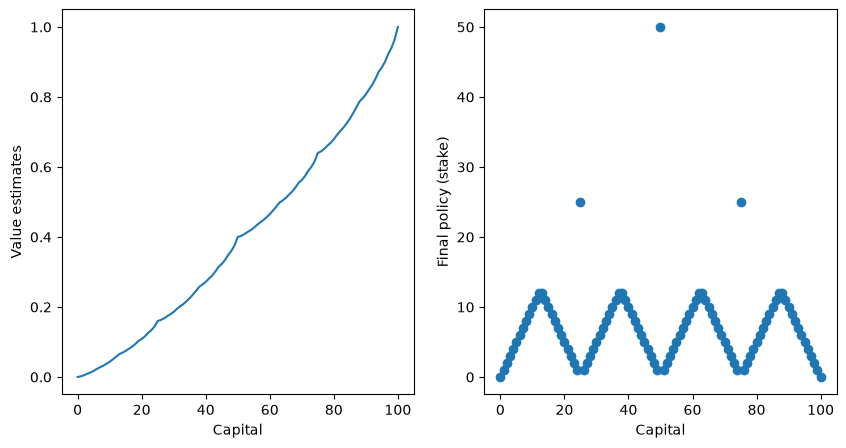

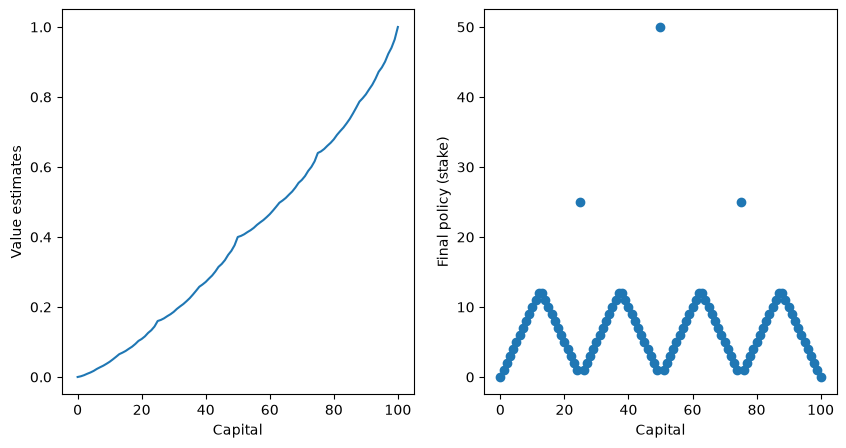

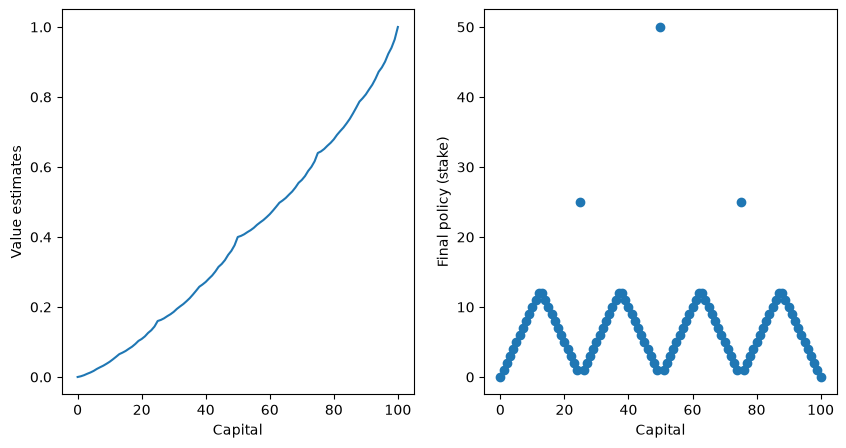

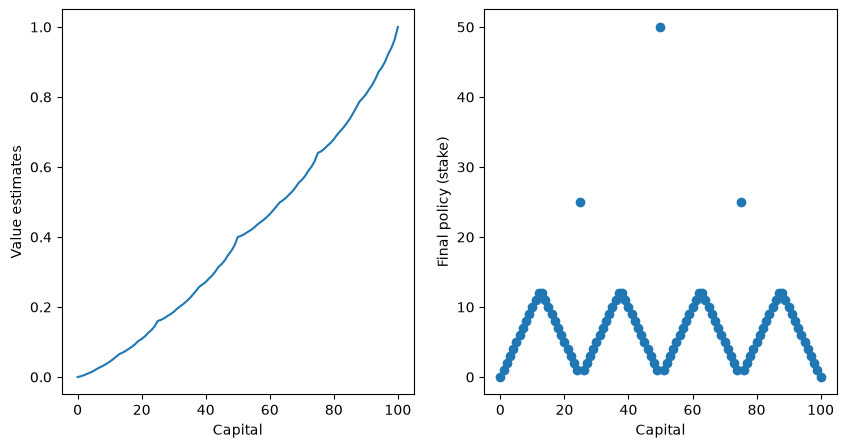

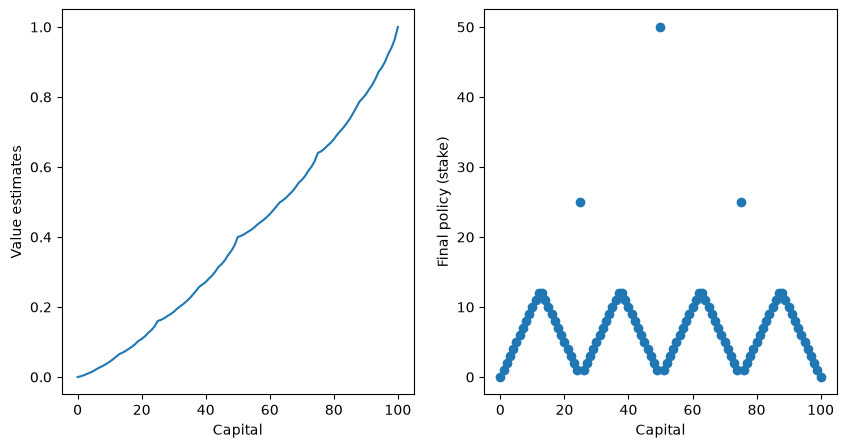

In [10]:
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

GOAL = 100 # objetivo
STATES = np.arange(GOAL + 1) # todos los estados, incluyendo s 0 and s 100
HEAD_PROB = 0.4 # Probabilidad de sacar cara

# Estados
state_value = np.zeros(GOAL + 1) # Valor esperado en cada estado (prob de ganar)
state_value[GOAL] = 1.0

# Array donde voy a guardar la política (cantidad a apostar para cada estado)
policy = np.zeros(GOAL + 1)

iteration = 0

niter = 12
while True:
    iteration += 1
    print('Iteración %d' % (iteration))

    delta = 0.0 # Evaluo el cambio de los valores, para ver si ya convergió a una solución
    for state in STATES[1:GOAL]: # recorro todos los estados
        # Obtener todas la acciones para el estado actual
        actions = np.arange(min(state, GOAL - state) + 1) # puedo apostar de 1 hasta lo que tengo, o lo que me falta para ganar
        action_returns = []
        for action in actions:
            action_returns.append(
                HEAD_PROB * state_value[state + action] + (1 - HEAD_PROB) * state_value[state - action])
            # para cada acción guardo la recompensa esperada.
            # Esto es la prob de ganar por el estado si gano + la prob de perder por el estado si pierdo.
        new_value = np.max(action_returns) # Guardo la acción que retorna la maxima recompensa
        delta += np.abs(state_value[state] - new_value) # Calculo la diferencia con la iteración anterior
        state_value[state] = new_value # guardo el nuevo resultado
        policy[state] = actions[np.argmax(np.round(action_returns[1:], 5)) + 1] # +1 porque la función me devuelve el indice del array
        # guardo mi politica como la acción que maximiza la probabilidad de ganar para cada estado


    _, axes = plt.subplots(1, 2, figsize=(10, 5))
    plt.subplots_adjust(wspace=0.2, hspace=0.2)
    axes = axes.flatten()

    # Plot Values
    plt.subplot(1, 2, 1)
    plt.plot(state_value)
    plt.xlabel('Capital')
    plt.ylabel('Value estimates')

    # Plot Policy
    plt.subplot(1, 2, 2)
    plt.scatter(STATES, policy)
    plt.xlabel('Capital')
    plt.ylabel('Final policy (stake)')

    if iteration == niter or delta < 1e-9:
        break


### Preguntas:
¿Por qué la política óptima tiende a esa forma?

## Aprender sin modelo del mundo

En el ejemplo anterior conocía el modelo del mundo, el cual tenía pocos estados y acciones. Podía calcular la función de valor de cada uno e iterar hasta encontrar la óptima.
Pero ¿qué hago cuando no tengo un modelo del mundo o los estados son demasiados como para iterar?

Los métodos de Monte Carlo permiten aprender la **función de valor de estado** de una política dada.
Recordemos que el **valor de un estado $v(s)$** es el **retorno esperado** —es decir, la **recompensa acumulada futura con descuento esperada**— al comenzar desde ese estado.
Una forma de estimarlo consiste en **promediar los retornos observados** después de las visitas a ese estado.
A medida que se observan más retornos, el promedio debería **converger al valor esperado**.
Esta idea es la base de todos los métodos de Monte Carlo.

Resumiendo, en Monte Carlo actualizo la función de valor con el promedio de los retornos observados después de las visitas a cada estado. Si las visitas al estado $s$ tienden a infinito, la función de valor converge a $v_\pi$.


## Métodos de diferencias temporales:
Con el método de Monte Carlo se tenía que esperar al fin del episodio para conocer el retorno $G_t$ y recién ahí actualizar $V(S_t)$. Los métodos de diferencias temporales buscan optimizar el proceso actualizando la función de valor en cada paso.

La función de valor en los métodos de diferencias temporales se actualiza de la siguiente forma:

$$
V(S_t) \leftarrow V(S_t) + \alpha \left[ R_{t+1} + \gamma V(S_{t+1}) - V(S_t) \right]
$$

Donde:

$V(S_t)$: Valor estimado del estado actual

$\alpha$: Controla qué tan rápido aprendemos (valores pequeños = aprendizaje lento pero estable)

$R_{t+1}$: Recompensa inmediata recibida

$\gamma$: Cuánto valoramos recompensas futuras vs. inmediatas

$V(S_{t+1})$: Nuestra estimación del valor del próximo estado

$[R_{t+1} + \gamma V(S_{t+1}) - V(S_t)]$: Error de diferencia temporal. Es la diferencia entre lo que esperábamos y lo que realmente obtuvimos más lo que esperamos obtener después

Los métodos de Diferencias Temporales (TD) presentan dos ventajas clave:

* Frente a la Programación Dinámica (DP): No necesitan un modelo previo del entorno (cómo responde a las acciones).

* Frente a Monte Carlo: Son incrementales y se pueden ejecutar online. Aprenden en cada paso, sin tener que esperar a que termine el episodio para conocer el retorno $G_t$. Esto es crucial en entornos con episodios muy largos, tareas continuas (sin episodios) o cuando se realizan acciones exploratorias, ya que acelera significativamente el aprendizaje.


### **Q-learning**:

Uno de los primeros avances en el aprendizaje por refuerzo fue el desarrollo de un algoritmo de control TD fuera de la política conocido como Q-learning (Watkins, 1989), definido por

$$
Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t) \right]
$$

donde:

- $Q(S_t, A_t)$: valor estimado de tomar la acción $A_t$ en el estado $S_t$  
- $\alpha$: tasa de aprendizaje (learning rate)  
- $R_{t+1}$: recompensa recibida tras ejecutar la acción  
- $\gamma$: factor de descuento (discount factor)  
- $\max_a Q(S_{t+1}, a)$: valor estimado máximo del siguiente estado  
- El término entre corchetes $[\,]$ es el **error de temporal-diferencia (TD error)**.


El algoritmo Q-learning es de aprendizaje por refuerzo fuera de política (off-policy). En cada paso, el agente observa el resultado de una acción, recibe una recompensa y llega a un nuevo estado, así actualiza su estimación del valor de esa acción combinando la recompensa inmediata con el valor máximo esperado de las acciones futuras. Con el tiempo, al explorar y actualizar según la fórmula de Q-learning, el agente converge hacia una política óptima que maximiza la recompensa acumulada esperada.

### Ejemplo: Encontrar la ruta óptima



In [11]:
# Ejemplo básico
import numpy as np
import random

# Parámetros
n_rows, n_cols = 5, 5
goal = (n_rows-1, n_cols-1)  # objetivo en la esquina inferior derecha
alpha = 0.1    # Factor de actualización
gamma = 0.9    # Factor de descuento
epsilon = 0.2  # epsilon greedy
episodes = 50

# Inicializamos tabla Q con ceros
Q = np.zeros((n_rows, n_cols, 4))  # 4 acciones

# Lista para guardar la recompensa por episodio
rewards_per_episode = []

# Función para elegir acción (ε-greedy)
def choose_action(state):
    if random.uniform(0,1) < epsilon:
        return random.randint(0,3)  # explorar
    else:
        return np.argmax(Q[state[0], state[1]])

# Función para ejecutar acción
def step(state, action):
    r, c = state
    if action == 0 and r > 0:        # arriba
        r -= 1
    elif action == 1 and r < n_rows-1:  # abajo
        r += 1
    elif action == 2 and c > 0:      # izquierda
        c -= 1
    elif action == 3 and c < n_cols-1:  # derecha
        c += 1

    new_state = (r, c)
    reward = 10 if new_state == goal else -1 # 10 si llego al objetivo, -1 por cada paso
    done = new_state == goal
    return new_state, reward, done

# Entrenamiento
for ep in range(episodes):
    state = (0,0)
    done = False
    total_reward = 0
    i = 0
    while not done:
        i += 1
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        # Actualizar Q
        Q[state[0], state[1], action] += alpha * (
            reward + gamma * np.max(Q[next_state[0], next_state[1]]) - Q[state[0], state[1], action]
        )
        state = next_state
        total_reward += reward
    rewards_per_episode.append(total_reward)
    print(f"ep {ep}. Pasos {i}")

# Política aprendida
policy = np.empty((n_rows, n_cols), dtype='<U1')
actions = ['↑','↓','←','→']

# Grafico la politica aprendida
for i in range(n_rows):
    for j in range(n_cols):
        if (i,j) == goal:
            policy[i,j] = 'G'
        else:
            policy[i,j] = actions[np.argmax(Q[i,j])]


print("Política aprendida:")
print(policy)


ep 0. Pasos 134
ep 1. Pasos 92
ep 2. Pasos 54
ep 3. Pasos 35
ep 4. Pasos 23
ep 5. Pasos 34
ep 6. Pasos 28
ep 7. Pasos 21
ep 8. Pasos 18
ep 9. Pasos 28
ep 10. Pasos 45
ep 11. Pasos 23
ep 12. Pasos 8
ep 13. Pasos 47
ep 14. Pasos 29
ep 15. Pasos 29
ep 16. Pasos 36
ep 17. Pasos 25
ep 18. Pasos 22
ep 19. Pasos 15
ep 20. Pasos 19
ep 21. Pasos 22
ep 22. Pasos 33
ep 23. Pasos 13
ep 24. Pasos 13
ep 25. Pasos 30
ep 26. Pasos 15
ep 27. Pasos 10
ep 28. Pasos 20
ep 29. Pasos 12
ep 30. Pasos 15
ep 31. Pasos 17
ep 32. Pasos 8
ep 33. Pasos 14
ep 34. Pasos 16
ep 35. Pasos 20
ep 36. Pasos 14
ep 37. Pasos 19
ep 38. Pasos 8
ep 39. Pasos 9
ep 40. Pasos 16
ep 41. Pasos 25
ep 42. Pasos 12
ep 43. Pasos 10
ep 44. Pasos 14
ep 45. Pasos 16
ep 46. Pasos 16
ep 47. Pasos 12
ep 48. Pasos 17
ep 49. Pasos 14
Política aprendida:
[['→' '→' '↓' '←' '↑']
 ['←' '↓' '↓' '↓' '↓']
 ['↓' '↓' '↓' '↓' '↓']
 ['←' '↓' '↓' '→' '↓']
 ['→' '→' '→' '→' 'G']]


Graficamos como fue evolucionando la recompensa en cada iteración:

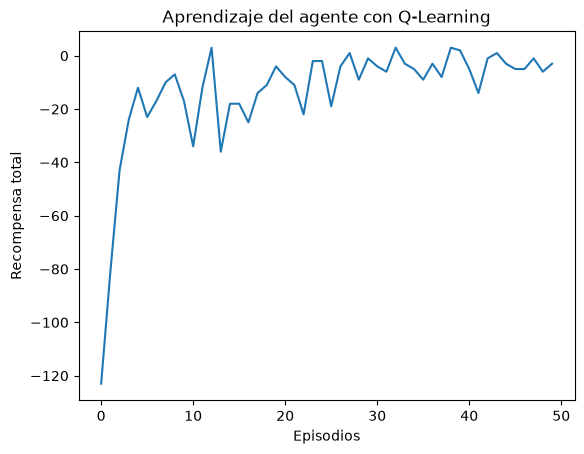

In [12]:
import matplotlib.pyplot as plt

plt.plot(rewards_per_episode)
plt.xlabel("Episodios")
plt.ylabel("Recompensa total")
plt.title("Aprendizaje del agente con Q-Learning")
plt.show()


### Preguntas:
¿Por qué en los primeros episodios el agente necesita muchos pasos para llegar al objetivo?

Q-learning es *off-policy*. ¿Qué política usa el agente para elegir sus acciones durante el entrenamiento, y cuál es la política que está aprendiendo?

En la próxima clase usamos Q-learning en un problema con más riesgo (CliffWalking), lo comparamos con SARSA, y vemos qué hacer cuando los estados son tantos que no entran en una tabla.